# Regresión Logística — Detección de fraude (Caso 1)

Se importan las librerías y la configuración compartida desde comun.py.

In [1]:
import sys
sys.path.append("..")  # el notebook está en modelos/, comun/ está un nivel arriba

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from comun.comun import RANDOM_STATE, CV, SCORING, FEATURES, cargar_train, make_prep

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.4f}".format)

Se carga el conjunto de entrenamiento con las 15 predictoras finales.

In [2]:
X, y = cargar_train()
print(f"X: {X.shape[0]:,} filas x {X.shape[1]} predictoras | fraudes: {y.sum()} ({y.mean()*100:.3f}%)")

X: 40,000 filas x 15 predictoras | fraudes: 727 (1.818%)


## 1. Pipeline

Se arma el pipeline con el preprocesamiento escalado y una Regresión Logística con pesos balanceados para compensar el desbalance de clases.

In [3]:
pipe = Pipeline([
    ("prep", make_prep(escalar=True)),
    ("modelo", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)),
])
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log1p', ...), ('log', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name

## 2. Validación cruzada y ajuste de hiperparámetros

Se busca la mejor regularización C con validación cruzada estratificada de 5 folds sobre train, con el preprocesamiento ajustado dentro de cada fold.

In [4]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(pipe, {"modelo__C": [0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10]}, cv=CV,
                    scoring=SCORING, refit="pr_auc", n_jobs=-1)
grid.fit(X, y)
print(f"Mejor C: {grid.best_params_['modelo__C']} | PR-AUC CV: {grid.best_score_:.4f}")

Mejor C: 0.001 | PR-AUC CV: 0.0505


Se comparan las métricas medias de CV para cada valor de C.

In [5]:
(pd.DataFrame(grid.cv_results_)
   .set_index("param_modelo__C")[[f"mean_test_{m}" for m in SCORING]]
   .rename(columns=lambda c: c.replace("mean_test_", ""))
   .rename_axis("C"))

,precision,recall,f1,roc_auc,pr_auc
C,,,,,
0.0000,0.0284,0.6135,0.0543,0.6421,0.0411
0.0001,0.0304,0.6341,0.0580,0.6589,0.0440
0.0010,0.0320,0.6286,0.0609,0.6806,0.0505
0.0100,0.0325,0.6162,0.0617,0.6821,0.0484
0.1000,0.0321,0.6052,0.0609,0.6811,0.0481
1.0000,0.0322,0.6065,0.0611,0.6810,0.0482
10.0000,0.0322,0.6065,0.0611,0.6810,0.0482


In [6]:
from comun.comun import resumen_cv

resumen = resumen_cv(grid)
resumen

,media,std
métrica,,
precision,0.0320,0.0032
recall,0.6286,0.0581
f1,0.0609,0.0061
roc_auc,0.6806,0.0262
pr_auc,0.0505,0.0076


## 3. Predicciones fuera de fold

Se obtienen probabilidades fuera de fold sobre train para construir la matriz de confusión sin tocar el test.

In [7]:
from sklearn.model_selection import cross_val_predict

oof = cross_val_predict(grid.best_estimator_, X, y, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
pred = (oof >= 0.5).astype(int)
print(f"Probabilidades fuera de fold: {len(oof):,} | predichas como fraude con umbral 0.5: {pred.sum():,}")

Probabilidades fuera de fold: 40,000 | predichas como fraude con umbral 0.5: 14,289


Se grafica la matriz de confusión fuera de fold con umbral 0.5.

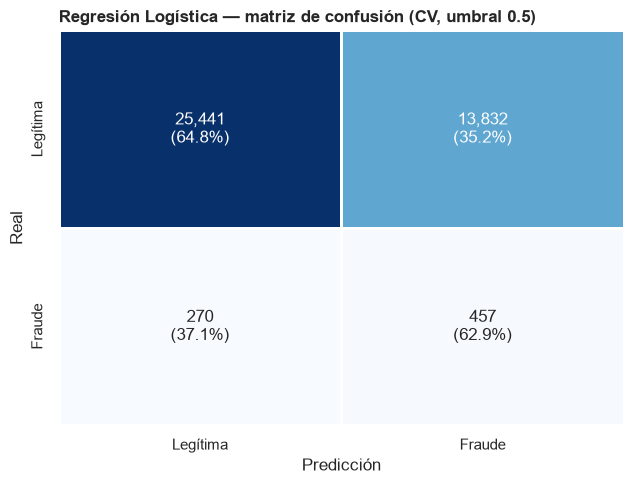

In [8]:
from sklearn.metrics import confusion_matrix
from comun.comun import guardar

cm = confusion_matrix(y, pred)
etiquetas = np.array([[f"{v:,}\n({v / fila.sum() * 100:.1f}%)" for v in fila] for fila in cm])
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(cm, annot=etiquetas, fmt="", cmap="Blues", cbar=False, linewidths=1,
            xticklabels=["Legítima", "Fraude"], yticklabels=["Legítima", "Fraude"], ax=ax)
ax.set(xlabel="Predicción", ylabel="Real")
ax.set_title("Regresión Logística — matriz de confusión (CV, umbral 0.5)", loc="left", fontweight="bold")
guardar("lr_matriz_confusion")

Se presenta la matriz de confusión en formato de tabla con los conteos de cada caso.

In [9]:
pd.DataFrame(cm, index=pd.Index(["Legítima", "Fraude"], name="Real"),
             columns=pd.Index(["Legítima", "Fraude"], name="Predicción"))

Predicción,Legítima,Fraude
Real,,
Legítima,25441,13832
Fraude,270,457


Se calculan la precisión, la sensibilidad (recall) y el F1-score de la clase fraude con umbral 0.5.

In [10]:
tn, fp, fn, tp = cm.ravel()
pd.DataFrame({"valor": {"Precision = VP / (VP + FP)": tp / (tp + fp),
                        "Sensibilidad (Recall) = VP / (VP + FN)": tp / (tp + fn),
                        "F1-score = 2·VP / (2·VP + FP + FN)": 2 * tp / (2 * tp + fp + fn)}})

,valor
Precision = VP / (VP + FP),0.0320
Sensibilidad (Recall) = VP / (VP + FN),0.6286
F1-score = 2·VP / (2·VP + FP + FN),0.0609


Se grafica la curva Precision-Recall fuera de fold frente a la línea base de un clasificador aleatorio, marcando el umbral 0.5.

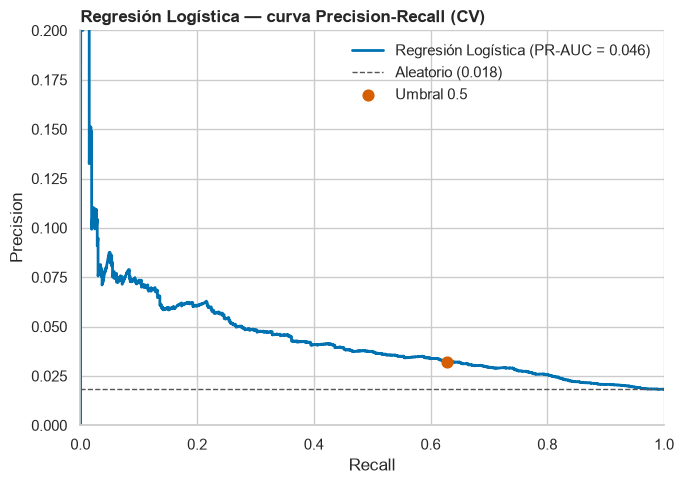

In [11]:
from sklearn.metrics import precision_recall_curve, average_precision_score

prec, rec, umb = precision_recall_curve(y, oof)
i05 = np.searchsorted(umb, 0.5)

fig, ax = plt.subplots(figsize=(7, 5))
sns.lineplot(x=rec, y=prec, estimator=None, sort=False, color="#0072B2", lw=2,
             label=f"Regresión Logística (PR-AUC = {average_precision_score(y, oof):.3f})", ax=ax)
ax.axhline(y.mean(), ls="--", color="#555", lw=1, label=f"Aleatorio ({y.mean():.3f})")
ax.scatter(rec[i05], prec[i05], color="#D55E00", s=60, zorder=3, label="Umbral 0.5")
ax.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 0.2))
ax.set_title("Regresión Logística — curva Precision-Recall (CV)", loc="left", fontweight="bold")
ax.legend(frameon=False)
sns.despine()
guardar("lr_curva_pr")

Se calcula cuántos fraudes se detectarían si el equipo antifraude revisara solo el porcentaje de transacciones con mayor probabilidad de fraude.

In [12]:
yv = y.values
filas = []
for pct in [1, 2, 5, 10, 20, 30]:
    u = np.quantile(oof, 1 - pct / 100)
    alerta = oof >= u
    tp = (alerta & (yv == 1)).sum()
    filas.append({"% revisado": pct, "umbral": u, "alertas": alerta.sum(),
                  "fraudes detectados": tp, "recall": tp / yv.sum(), "precision": tp / alerta.sum()})
pd.DataFrame(filas).set_index("% revisado")

,umbral,alertas,fraudes detectados,recall,precision
% revisado,,,,,
1,0.7391,400,32,0.0440,0.0800
2,0.7087,800,61,0.0839,0.0762
5,0.6618,2000,122,0.1678,0.0610
10,0.6171,4000,201,0.2765,0.0503
20,0.5611,8000,317,0.4360,0.0396
30,0.5208,12000,415,0.5708,0.0346


## 4. Variables más influyentes

Se calculan los coeficientes del modelo final y su odds ratio, que indica cuántas veces cambian las probabilidades de fraude al aumentar la variable.

In [13]:
modelo = grid.best_estimator_
coefs = pd.DataFrame({"coeficiente": modelo.named_steps["modelo"].coef_[0]},
                     index=modelo.named_steps["prep"].get_feature_names_out())
coefs["odds ratio"] = np.exp(coefs["coeficiente"])
coefs = coefs.reindex(coefs["coeficiente"].abs().sort_values(ascending=False).index)
coefs

,coeficiente,odds ratio
country_EC,-0.4662,0.6274
new_device,0.3387,1.4031
card_present,-0.2996,0.7411
merchant_category_viajes,0.2797,1.3227
amount_usd,0.1784,1.1953
channel_POS,-0.1551,0.8563
amount_vs_avg,0.1402,1.1505
merchant_category_otros,-0.1237,0.8836
hour,-0.1219,0.8852
country_CO,0.1188,1.1262


Se grafican los 15 coeficientes de mayor magnitud, en rojo los que aumentan el riesgo de fraude y en azul los que lo reducen.

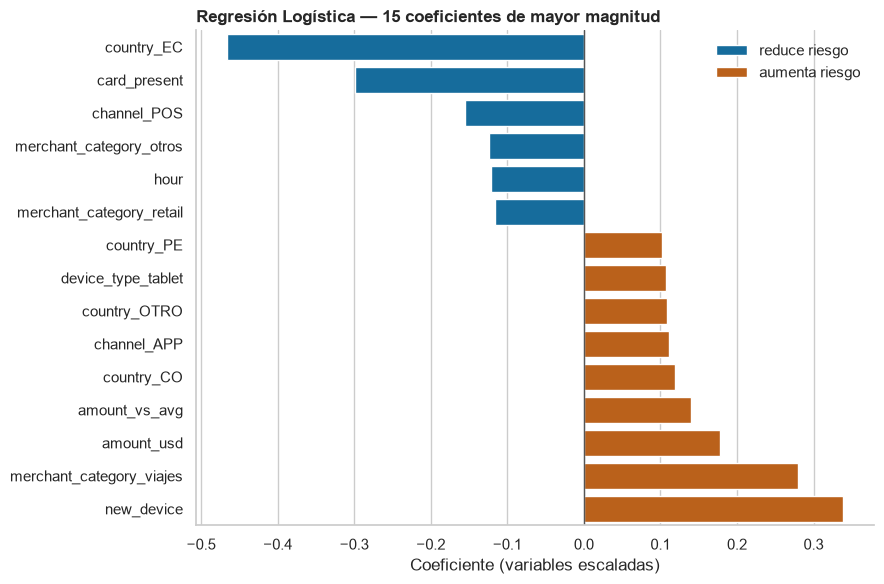

In [14]:
top = coefs["coeficiente"].head(15).sort_values()
efecto = np.where(top > 0, "aumenta riesgo", "reduce riesgo")

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=top.values, y=top.index, hue=efecto,
            palette={"aumenta riesgo": "#D55E00", "reduce riesgo": "#0072B2"}, ax=ax)
ax.axvline(0, color="#555", lw=1)
ax.set(xlabel="Coeficiente (variables escaladas)", ylabel="")
ax.set_title("Regresión Logística — 15 coeficientes de mayor magnitud", loc="left", fontweight="bold")
ax.legend(title=None, frameon=False)
sns.despine()
guardar("lr_coeficientes")

## 5. Experimento: versión mejorada

Se crean variables de hora que capturan el riesgo de madrugada: seno y coseno de la hora (ciclo de 24 h) y una marca de 23:00 a 04:00.

In [15]:
from sklearn.preprocessing import FunctionTransformer
from comun.comun import hora_features, nombres_hora

hora = FunctionTransformer(hora_features, feature_names_out=nombres_hora)
ejemplo = X[["hour"]].drop_duplicates().sort_values("hour")
pd.DataFrame(hora.fit_transform(ejemplo), columns=hora.get_feature_names_out(["hour"]), index=ejemplo["hour"])

,hour_sin,hour_cos,madrugada
hour,,,
0,0.0000,1.0000,1.0000
1,0.2588,0.9659,1.0000
2,0.5000,0.8660,1.0000
3,0.7071,0.7071,1.0000
4,0.8660,0.5000,1.0000
5,0.9659,0.2588,0.0000
6,1.0000,0.0000,0.0000
7,0.9659,-0.2588,0.0000
8,0.8660,-0.5000,0.0000


Se arma el preprocesamiento mejorado, que reemplaza hour por sus variables cíclicas y agrega interacciones de a pares entre todas las columnas.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from comun.comun import LOG1P, LOG, NUM_RESTO, CAT, BIN

def log_y_escala(f):
    return Pipeline([("log", FunctionTransformer(f, feature_names_out="one-to-one")), ("sc", StandardScaler())])

prep_v2 = ColumnTransformer([
    ("log1p", log_y_escala(np.log1p), LOG1P),
    ("log", log_y_escala(np.log), LOG),
    ("num", StandardScaler(), [c for c in NUM_RESTO if c != "hour"]),
    ("hora", hora, ["hour"]),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
    ("bin", "passthrough", BIN),
], verbose_feature_names_out=False)

pipe_v2 = Pipeline([
    ("prep", prep_v2),
    ("inter", PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)),
    ("modelo", LogisticRegression(solver="liblinear", max_iter=2000, random_state=RANDOM_STATE)),
])
print(f"Columnas: {prep_v2.fit(X).transform(X.head(1)).shape[1]} tras el preprocesamiento → "
      f"{pipe_v2[:-1].fit(X).transform(X.head(1)).shape[1]} con interacciones")

Columnas: 37 tras el preprocesamiento → 703 con interacciones


Se buscan la regularización C, el tipo de penalización (L2 o L1) y el peso de la clase fraude con la misma validación cruzada de 5 folds.

In [17]:
grid_v2 = GridSearchCV(pipe_v2, {"modelo__C": [0.001, 0.01, 0.1],
                                 "modelo__l1_ratio": [0, 1],
                                 "modelo__class_weight": ["balanced", {0: 1, 1: 10}]},
                       cv=CV, scoring=SCORING, refit="pr_auc", n_jobs=-1)
grid_v2.fit(X, y)
print(f"Mejores parámetros: {grid_v2.best_params_} | PR-AUC CV: {grid_v2.best_score_:.4f}")

Mejores parámetros: {'modelo__C': 0.01, 'modelo__class_weight': {0: 1, 1: 10}, 'modelo__l1_ratio': 1} | PR-AUC CV: 0.0544


Se comparan las métricas de CV de la versión base y la versión mejorada.

In [18]:
pd.concat({"base": resumen_cv(grid), "mejorada": resumen_cv(grid_v2)}, axis=1)

base        mejorada       
           media    std    media    std
métrica                                
precision 0.0320 0.0032   0.0796 0.0470
recall    0.6286 0.0581   0.0262 0.0160
f1        0.0609 0.0061   0.0394 0.0239
roc_auc   0.6806 0.0262   0.6904 0.0206
pr_auc    0.0505 0.0076   0.0544 0.0123

Se elige, con las predicciones fuera de fold, el umbral que maximiza F1 para equilibrar fraudes detectados y falsas alarmas.

In [19]:
oof_v2 = cross_val_predict(grid_v2.best_estimator_, X, y, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
p2, r2, u2 = precision_recall_curve(y, oof_v2)
f1 = 2 * p2 * r2 / (p2 + r2 + 1e-12)
k = f1[:-1].argmax()
print(f"Umbral óptimo F1: {u2[k]:.3f} | Precision: {p2[k]:.3f} | Recall: {r2[k]:.3f} | F1: {f1[k]:.3f} | "
      f"alertas: {(oof_v2 >= u2[k]).mean()*100:.1f}% de las transacciones")

Umbral óptimo F1: 0.321 | Precision: 0.072 | Recall: 0.194 | F1: 0.105 | alertas: 4.9% de las transacciones


## 6. Guardado

Se guarda la versión base como final, por ser más simple e interpretable y porque la mejorada no supera la variación entre folds, junto con sus métricas de CV y sus probabilidades fuera de fold.

In [20]:
from comun.comun import guardar_resultados

guardar_resultados("regresion_logistica", grid.best_estimator_, resumen, y, oof)

['cv_regresion_logistica.csv',
 'oof_regresion_logistica.csv',
 'regresion_logistica.joblib']

## 7. Conclusiones

- **Modelo final:** versión base (C = 0.001, penalización L2, `class_weight="balanced"`, 35 columnas).
- **Rendimiento en CV (media ± desviación):** PR-AUC 0.051 ± 0.008 (2.8× el azar), ROC-AUC 0.681 ± 0.026, Recall 0.63 ± 0.06 y Precision 0.032 ± 0.003 con umbral 0.5.
- **Con umbral 0.5:** detecta el 63% de los fraudes, pero alerta el 36% de las transacciones (unas 30 falsas alarmas por fraude), lo que es inmanejable para un equipo antifraude.
- **Según capacidad de revisión:** revisando el 5% de mayor riesgo se detecta el 17% de los fraudes con precisión del 6.1%; revisando el 10%, el 28% con precisión del 5.0%.
- **Variables más influyentes:** país distinto de EC, dispositivo nuevo, tarjeta no presente, categoría viajes y montos altos aumentan el riesgo; `ip_risk_score`, `distance_home_km` y `device_type` casi no influyen, en línea con el EDA.
- **Experimento (versión mejorada):** hora cíclica + marca de madrugada + interacciones de a pares (703 columnas) con L1, C = 0.01 y peso de fraude ×10 obtuvo PR-AUC 0.054 ± 0.012 y ROC-AUC 0.690 ± 0.021; con su umbral óptimo de F1 (0.32) alerta el 4.9% de las transacciones con precisión del 7.2% y recall del 19.4%. La mejora queda dentro de la variación entre folds, por lo que se descarta por parsimonia e interpretabilidad.
- **Limitación:** al ser un modelo lineal no capta bien las interacciones ni las relaciones no lineales; queda como modelo base de comparación para los árboles y el boosting.